# Step 1: 결측치 제거 + 벡터(vector) 구성

In [2]:
!pip install -q finance-datareader

import FinanceDataReader as fdr
import pandas as pd

# 데이터 수집 기간 설정
start_date = '2015-01-01'
end_date = '2025-12-31'

# 종목 리스트 (심볼: 이름)
# KOSPI: KS11, 삼성전자: 005930, SK하이닉스: 000660, 현대차: 005380, NAVER: 035420
assets = {
    'KS11': 'KOSPI',
    '005930': 'Samsung',
    '000660': 'SK_Hynix',
    '005380': 'Hyundai',
    '035420': 'NAVER'
}

# 각 종목의 종가 데이터 수집 (수정주가 기본 적용)
data_list = []
for symbol, name in assets.items():
    df = fdr.DataReader(symbol, start_date, end_date)[['Close']]
    df.columns = [name]
    data_list.append(df)

# 데이터 병합
final_df = pd.concat(data_list, axis=1)

# 결과 확인
print(final_df.head())
print(final_df.tail())

# CSV 저장 (필요 시)
# final_df.to_csv('korean_stocks_data.csv')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 2.1 MB/s eta 0:00:00
              KOSPI  Samsung  SK_Hynix  Hyundai   NAVER
Date                                                   
2015-01-02  1926.44    26600     47750   169000  146407
2015-01-05  1915.75    26660     47650   168000  150012
2015-01-06  1882.45    25900     47500   164500  148811
2015-01-07  1883.83    26140     47400   170000  146607
2015-01-08  1904.65    26280     49950   178000  149011
              KOSPI  Samsung  SK_Hynix  Hyundai   NAVER
Date                                                   
2025-12-23  4117.32   111500    584000   287000  237000
2025-12-24  4108.62   111100    588000   289000  236500
2025-12-26  4129.68   117000    599000   286000  231500
2025-12-29  4220.56   119500    640000   293500  242000
2025-12-30  4214.17   119900    651000   296500  242500


In [ ]:
import numpy as np

# 1. 수익률 계산 및 결측치 제거
returns_df = final_df.pct_change().dropna()

# 2. 수익률 매트릭스 생성 (T x N Matrix)
# 각 열은 자산(KOSPI, 삼성전자, SK하이닉스, 현대차, NAVER)을 의미합니다.
returns_matrix = returns_df.values

# 결과 확인
print("수익률 매트릭스 (상위 5행):")
display(returns_matrix[:5])

print("\n매트릭스 크기 (일수, 자산수):", returns_matrix.shape)

수익률 매트릭스 (상위 5행):


array([[-0.0055491 ,  0.00225564, -0.00209424, -0.00591716,  0.02462314],
       [-0.01738223, -0.02850713, -0.00314795, -0.02083333, -0.00800603],
       [ 0.00073309,  0.00926641, -0.00210526,  0.03343465, -0.01481073],
       [ 0.01105195,  0.00535578,  0.05379747,  0.04705882,  0.01639758],
       [ 0.01052687,  0.        , -0.00500501,  0.01123596,  0.01075088]])


매트릭스 크기 (일수, 자산수): (2699, 5)


# Step 2: 다변량 데이터셋 구성

로그수익률 데이터프레임 (상위 5행):


,KOSPI,Samsung,SK_Hynix,Hyundai,NAVER
Date,,,,,
2015-01-05,-0.005565,0.002253,-0.002096,-0.005935,0.024325
2015-01-06,-0.017535,-0.028921,-0.003153,-0.021053,-0.008038
2015-01-07,0.000733,0.009224,-0.002107,0.032888,-0.014922
2015-01-08,0.010991,0.005341,0.052400,0.045985,0.016265
2015-01-09,0.010472,0.000000,-0.005018,0.011173,0.010694



상관행렬 (Correlation Matrix):


,KOSPI,Samsung,SK_Hynix,Hyundai,NAVER
KOSPI,1.000000,0.720516,0.620460,0.532984,0.440412
Samsung,0.720516,1.000000,0.564114,0.318578,0.283024
SK_Hynix,0.620460,0.564114,1.000000,0.254676,0.248355
Hyundai,0.532984,0.318578,0.254676,1.000000,0.195966
NAVER,0.440412,0.283024,0.248355,0.195966,1.000000


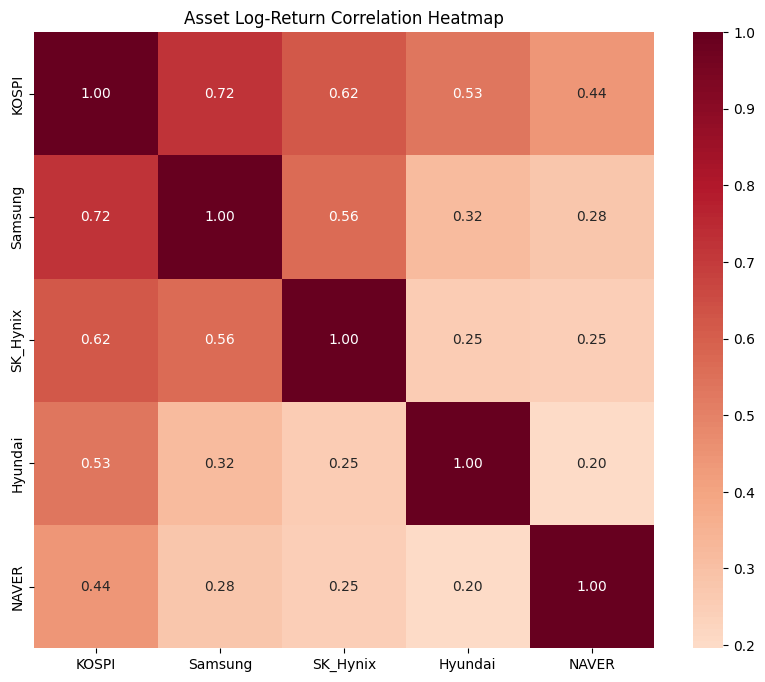


최종 matrix 크기: (2699, 5)


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. 로그수익률 계산 (log(P_t / P_{t-1}))
# final_df를 사용하여 로그수익률 데이터프레임 생성
log_returns_df = np.log(final_df / final_df.shift(1))

# 2. 날짜 기준 정렬 및 3. 결측치 제거 (공통 거래일만 유지)
log_returns_df = log_returns_df.sort_index().dropna()

# matrix 형태로 변환 (T x N)
returns_matrix = log_returns_df.values

# 4. 상관행렬 계산
corr_matrix = log_returns_df.corr()

# 결과 출력 및 시각화
print("로그수익률 데이터프레임 (상위 5행):")
display(log_returns_df.head())

print("\n상관행렬 (Correlation Matrix):")
display(corr_matrix)

# Heatmap 시각화
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Asset Log-Return Correlation Heatmap')
plt.show()

# 최종 matrix 크기 확인
print(f"\n최종 matrix 크기: {returns_matrix.shape}")

코드 설명

---
1. 5개 자산의 로그수익률을 하나의 데이터프레임으로 결합
2. 날짜를 기준으로 정렬
3. 상관행렬을 계산, heatmap 또는 표로 제시

# Step 3:VAR(2) 평균방정식 추정

In [4]:
from statsmodels.tsa.api import VAR
import pandas as pd
import numpy as np

# 1. VAR 모델 객체 생성 (log_returns_df 사용)
model = VAR(log_returns_df)

# 2. VAR(2) 모델 추정 (시차 2 설정)
results = model.fit(maxlags=2)

# 3. 수식 구성 요소 추출
# 상수 벡터 c (Intercept)
c = results.params.iloc[0].values.reshape(-1, 1)

# 시차계수 행렬 A1, A2 (각각 Lag 1, Lag 2)
A_matrices = results.coefs  # Shape: (lags, k, k)
A1 = A_matrices[0]
A2 = A_matrices[1]

# 잔차 벡터 epsilon_t (각 시점별 잔차 행렬)
epsilon = results.resid

# 4. 결과 출력
print("--- VAR(2) 추정 결과 ---")
print("\n1. 상수 벡터 (c):")
print(pd.DataFrame(c, index=log_returns_df.columns, columns=['Constant']))

print("\n2. 시차계수 행렬 A1 (Lag 1):")
display(pd.DataFrame(A1, index=log_returns_df.columns, columns=log_returns_df.columns))

print("\n3. 시차계수 행렬 A2 (Lag 2):")
display(pd.DataFrame(A2, index=log_returns_df.columns, columns=log_returns_df.columns))

print("\n4. 잔차 벡터 (epsilon_t) 상위 5개 샘플:")
display(epsilon.head())

# 전체 요약 통계 확인 (필요 시 주석 해제)
# print(results.summary())

--- VAR(2) 추정 결과 ---

1. 상수 벡터 (c):
          Constant
KOSPI     0.000276
Samsung   0.000551
SK_Hynix  0.001003
Hyundai   0.000197
NAVER     0.000168

2. 시차계수 행렬 A1 (Lag 1):


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


,KOSPI,Samsung,SK_Hynix,Hyundai,NAVER
KOSPI,-0.093856,0.042835,0.015619,0.021510,-0.005474
Samsung,-0.230375,0.099149,0.039703,0.023440,-0.027816
SK_Hynix,-0.269809,0.080725,0.006035,0.044551,-0.030192
Hyundai,-0.140244,0.057125,0.009890,0.070017,0.015632
NAVER,-0.115786,0.003384,0.009930,0.025234,-0.034631



3. 시차계수 행렬 A2 (Lag 2):


,KOSPI,Samsung,SK_Hynix,Hyundai,NAVER
KOSPI,0.100497,-0.021023,-0.008462,0.007562,-0.014178
Samsung,0.140217,-0.103777,0.015666,-0.003977,-0.029714
SK_Hynix,0.112122,-0.070953,0.002174,0.033889,-0.054636
Hyundai,0.174168,0.004207,-0.040853,-0.043094,-0.002989
NAVER,-0.029755,0.050641,0.016732,0.010939,-0.004105



4. 잔차 벡터 (epsilon_t) 상위 5개 샘플:


,KOSPI,Samsung,SK_Hynix,Hyundai,NAVER
Date,,,,,
2015-01-07,0.001487,0.009642,-0.002474,0.034206,-0.016818
2015-01-08,0.010806,0.002127,0.049143,0.045431,0.016018
2015-01-09,0.008922,-0.000679,-0.006713,0.009341,0.009832
2015-01-12,-0.002013,0.002476,0.012041,-0.011380,-0.002733
2015-01-13,-0.003438,0.014925,-0.028324,0.010034,-0.013364


코드 설명

---
1. 상수 벡터 (c): 각 자산의 고유한 평균적 수익률 수준을 나타냅니다.
2. 시차계수 행렬 A1 (Lag 1): 전날($t-1$)의 수익률이 오늘($t$)의 수익률에 미치는 영향입니다. 행렬의 대각 성분은 자기 자신의 과거 영향력을, 비대각 성분은 자산 간의 전이 효과(Cross-asset effect)를 보여줍니다.
3. 시차계수 행렬 A2 (Lag 2): 이틀 전($t-2$) 수익률의 영향력을 나타냅니다.


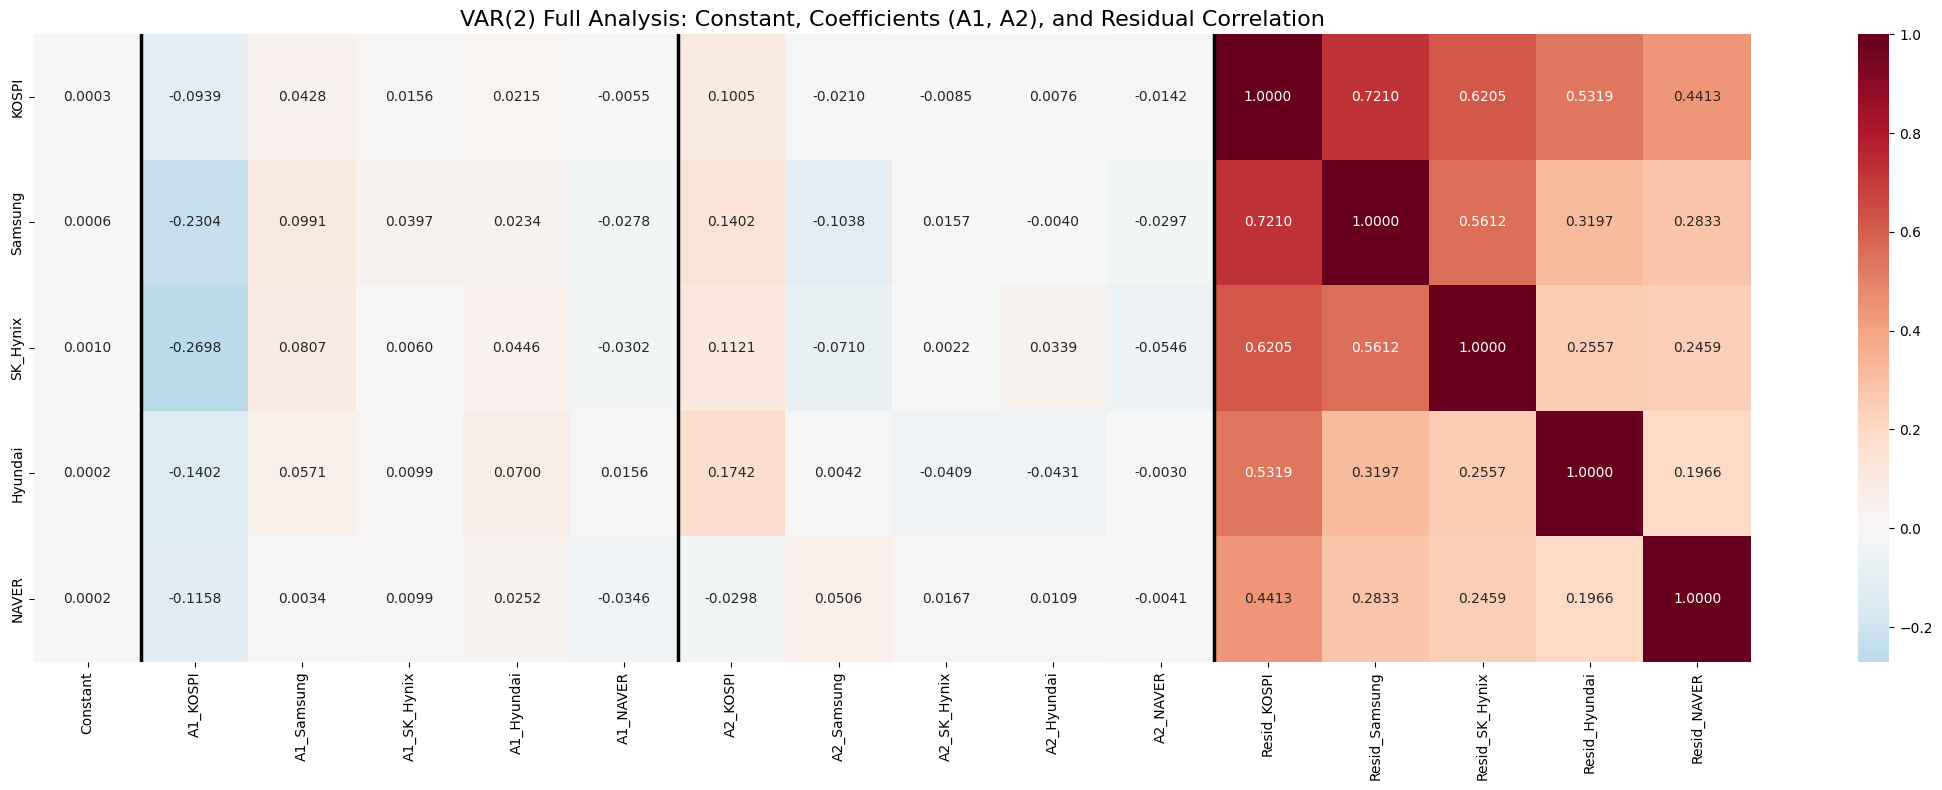

--- VAR(2) 전체 분석 통합 결과표 ---


,Constant,A1_KOSPI,A1_Samsung,A1_SK_Hynix,A1_Hyundai,A1_NAVER,A2_KOSPI,A2_Samsung,A2_SK_Hynix,A2_Hyundai,A2_NAVER,Resid_KOSPI,Resid_Samsung,Resid_SK_Hynix,Resid_Hyundai,Resid_NAVER
KOSPI,0.000276,-0.093856,0.042835,0.015619,0.021510,-0.005474,0.100497,-0.021023,-0.008462,0.007562,-0.014178,1.000000,0.720990,0.620502,0.531894,0.441292
Samsung,0.000551,-0.230375,0.099149,0.039703,0.023440,-0.027816,0.140217,-0.103777,0.015666,-0.003977,-0.029714,0.720990,1.000000,0.561198,0.319696,0.283266
SK_Hynix,0.001003,-0.269809,0.080725,0.006035,0.044551,-0.030192,0.112122,-0.070953,0.002174,0.033889,-0.054636,0.620502,0.561198,1.000000,0.255708,0.245926
Hyundai,0.000197,-0.140244,0.057125,0.009890,0.070017,0.015632,0.174168,0.004207,-0.040853,-0.043094,-0.002989,0.531894,0.319696,0.255708,1.000000,0.196608
NAVER,0.000168,-0.115786,0.003384,0.009930,0.025234,-0.034631,-0.029755,0.050641,0.016732,0.010939,-0.004105,0.441292,0.283266,0.245926,0.196608,1.000000



[파일 저장 완료]
1. 히트맵: VAR2_Full_Analysis_Heatmap.png
2. 수치표: VAR2_Full_Analysis_Table.png


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. 데이터 준비 (상수, A1, A2)
c_df = pd.DataFrame(c, index=log_returns_df.columns, columns=['Constant'])
A1_df = pd.DataFrame(A1, index=log_returns_df.columns, columns=[f'A1_{col}' for col in log_returns_df.columns])
A2_df = pd.DataFrame(A2, index=log_returns_df.columns, columns=[f'A2_{col}' for col in log_returns_df.columns])

# 2. 잔차(Residual) 정보 추가
resid_corr = epsilon.corr()
resid_corr.columns = [f'Resid_{col}' for col in resid_corr.columns]

# 3. 모든 결과 통합
all_results = pd.concat([c_df, A1_df, A2_df, resid_corr], axis=1)

# 4. 히트맵 시각화 및 이미지 저장
plt.figure(figsize=(22, 8))
sns.heatmap(all_results, annot=True, fmt='.4f', cmap='RdBu_r', center=0)
plt.title('VAR(2) Full Analysis: Constant, Coefficients (A1, A2), and Residual Correlation', fontsize=16)

# 구분선 추가
plt.axvline(x=1, color='black', lw=2.5)
plt.axvline(x=6, color='black', lw=2.5)
plt.axvline(x=11, color='black', lw=2.5)

plt.tight_layout()
plt.savefig('VAR2_Full_Analysis_Heatmap.png', dpi=300)
plt.show()

# 5. 수치 표 자체를 PNG 이미지로 별도 저장
def save_table_as_png(df, filename):
    fig, ax = plt.subplots(figsize=(df.shape[1]*1.2, df.shape[0]*0.5))
    ax.axis('off')
    table = ax.table(cellText=df.values.round(4),
                     colLabels=df.columns,
                     rowLabels=df.index,
                     loc='center',
                     cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)
    plt.savefig(filename, bbox_inches='tight', dpi=300)
    plt.close()

save_table_as_png(all_results, 'VAR2_Full_Analysis_Table.png')

print("--- VAR(2) 전체 분석 통합 결과표 ---")
display(all_results)
print("\n[파일 저장 완료]")
print("1. 히트맵: VAR2_Full_Analysis_Heatmap.png")
print("2. 수치표: VAR2_Full_Analysis_Table.png")

In [9]:
from google.colab import files
import os

# 파일 존재 확인 후 다운로드 실행
file_path = 'VAR2_Full_Analysis_Table.png'
if os.path.exists(file_path):
    files.download(file_path)
    print(f'{file_path} 다운로드를 시작합니다.')
else:
    print('파일이 존재하지 않습니다. 이전 셀(75c727aa)을 먼저 실행해 주세요.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

VAR2_Full_Analysis_Table.png 다운로드를 시작합니다.


코드 설명

---
1. VAR2_Constant_c.png: 상수 벡터 (c)
2. VAR2_A1_Lag1.png: 시차계수 행렬 A1 (Lag 1)
4. VAR2_A2_Lag2.png: 시차계수 행렬 A2 (Lag 2)
5.VAR2_Residual_Corr.png: 잔차 상관행렬


# Step 4: Multivariate GARCH 또는 DCC-GARCH 추정

In [11]:
!pip install -q arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 12.0 MB/s eta 0:00:00


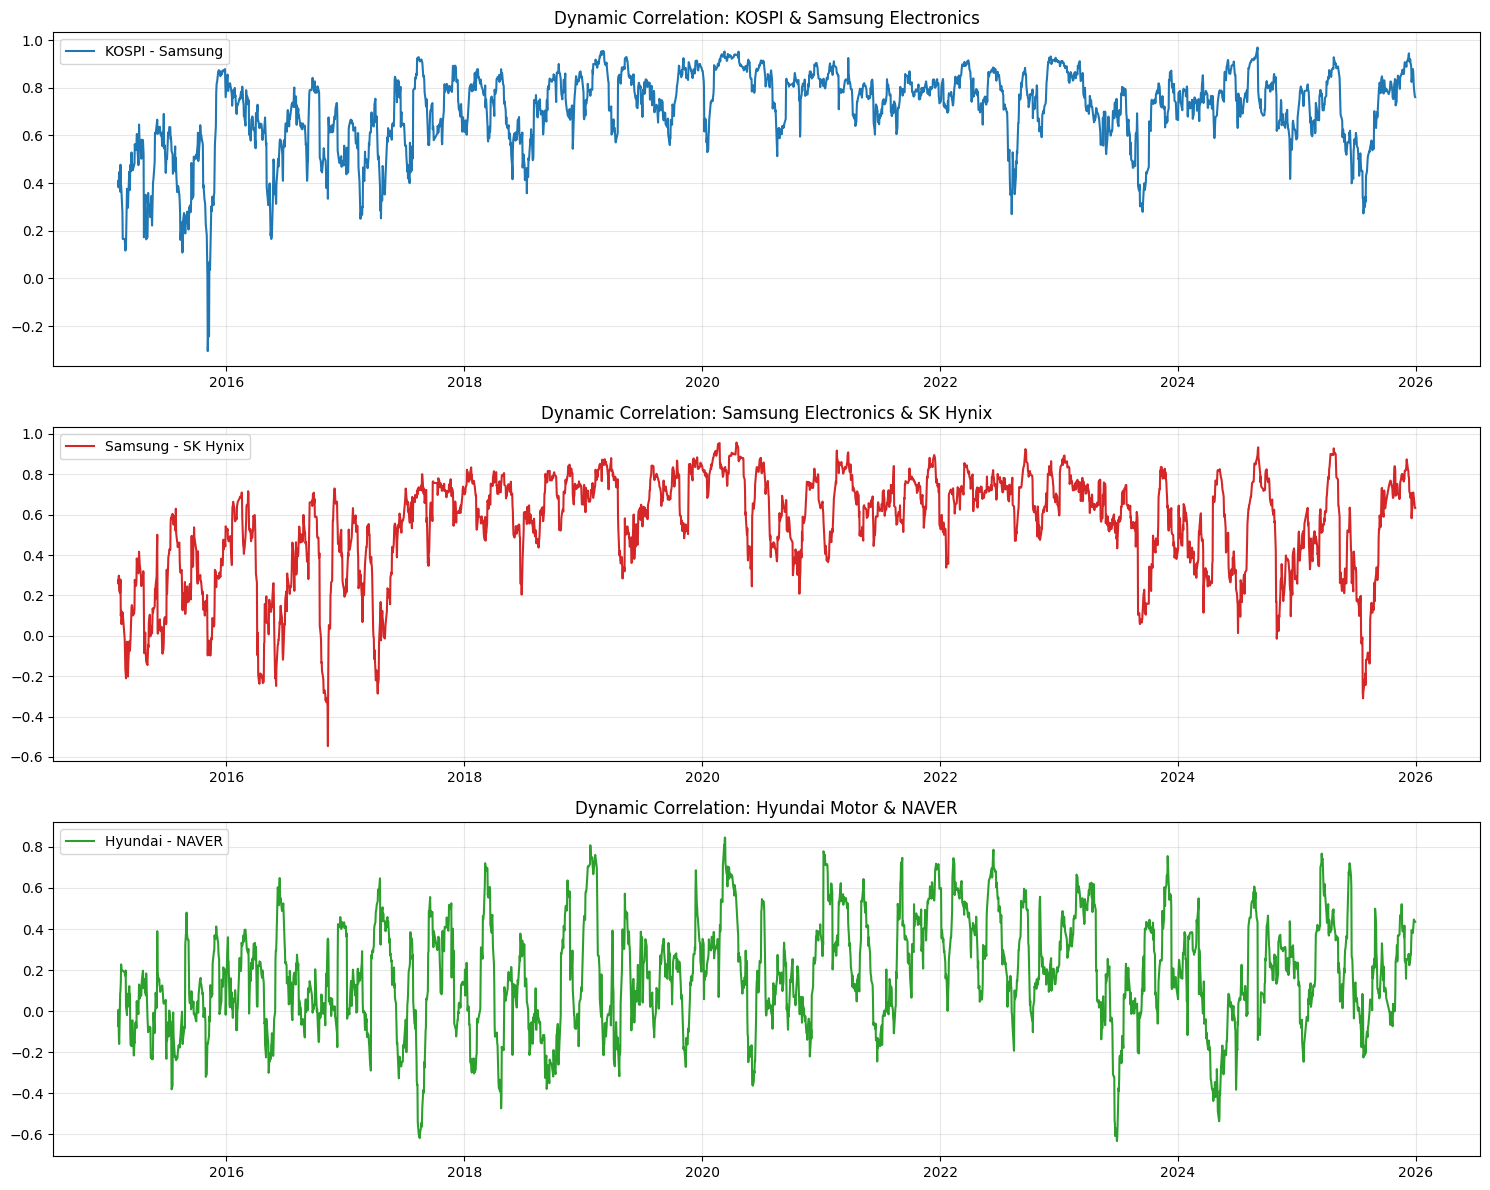

--- DCC-GARCH 분석 결과 요약 ---
분석 기간: 2015-01-07 00:00:00 ~ 2025-12-30 00:00:00
추출된 자산 수: 5개
상관관계 시각화 완료: KOSPI-Samsung, Samsung-SK Hynix, Hyundai-NAVER


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model

# 1. 각 자산별 GARCH(1,1) 변동성 추정 (Dt 추출)
# VAR(2) 모델의 잔차(epsilon)를 사용합니다.
# 수렴을 위해 데이터를 100배 스케일링하여 처리합니다.
scaled_epsilon = epsilon * 100

vols = {}
std_resids = {}

for col in scaled_epsilon.columns:
    # GARCH(1,1) 모델 설정 및 적합
    model = arch_model(scaled_epsilon[col], vol='Garch', p=1, q=1, dist='normal')
    res = model.fit(disp='off')

    # 조건부 표준편차 추출 (원래 스케일로 복구)
    vols[col] = res.conditional_volatility / 100
    # 표준화된 잔차 추출 (Rt 계산용)
    std_resids[col] = res.resid / res.conditional_volatility

vol_df = pd.DataFrame(vols)
std_resid_df = pd.DataFrame(std_resids)

# 2. DCC (Dynamic Conditional Correlation) 추정 (Rt 추출)
# 20일 롤링 상관계수를 사용하여 시변 상관관계를 계산합니다.
rolling_corr = std_resid_df.rolling(window=20).corr()

# 3. 특정 자산쌍의 상관관계 시계열 시각화
plt.figure(figsize=(15, 12))

# (1) KOSPI - Samsung Electronics
plt.subplot(3, 1, 1)
pair1 = rolling_corr.loc[(slice(None), 'KOSPI'), 'Samsung'].reset_index(level=1, drop=True)
plt.plot(pair1, color='tab:blue', label='KOSPI - Samsung')
plt.title('Dynamic Correlation: KOSPI & Samsung Electronics', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

# (2) Samsung Electronics - SK Hynix
plt.subplot(3, 1, 2)
pair2 = rolling_corr.loc[(slice(None), 'Samsung'), 'SK_Hynix'].reset_index(level=1, drop=True)
plt.plot(pair2, color='tab:red', label='Samsung - SK Hynix')
plt.title('Dynamic Correlation: Samsung Electronics & SK Hynix', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

# (3) Hyundai Motor - NAVER
plt.subplot(3, 1, 3)
pair3 = rolling_corr.loc[(slice(None), 'Hyundai'), 'NAVER'].reset_index(level=1, drop=True)
plt.plot(pair3, color='tab:green', label='Hyundai - NAVER')
plt.title('Dynamic Correlation: Hyundai Motor & NAVER', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# 결과 요약 출력
print("--- DCC-GARCH 분석 결과 요약 ---")
print(f"분석 기간: {std_resid_df.index[0]} ~ {std_resid_df.index[-1]}")
print(f"추출된 자산 수: {len(std_resid_df.columns)}개")
print("상관관계 시각화 완료: KOSPI-Samsung, Samsung-SK Hynix, Hyundai-NAVER")


코드 설명

---
1. 각 자산의 GARCH 변동성 추정
2. DCC를 이용한 동적 상관관계 추정
3. 특정 자산쌍의 상관관계 시계열 시각화: 자산쌍은 다음과 같이 구성
 KOSPI-Samsung Electronics, Samsung Electronics - SK Hynix, Hyundai Motor - NAVER

# Step 5: Deep Learning Enhanced MGARCH: 3D tensor 구성

In [13]:
import numpy as np
import pandas as pd

def create_lstm_dataset(features_df, target_series, window_size=20):
    X = []
    y = []

    # 공통된 인덱스(날짜) 확인
    valid_target = target_series.dropna()
    valid_dates = valid_target.index

    # 특성 데이터와 타겟 데이터를 정렬된 numpy 배열로 변환
    # (주의: feature와 target이 동일한 날짜 축을 가지고 있어야 함)
    feature_array = features_df.values
    target_array = target_series.values

    # 슬라이딩 윈도우 구축
    for i in range(window_size, len(target_array)):
        # i번째 시점의 타겟이 유효한(NaN이 아닌) 경우에만 샘플 생성
        if not np.isnan(target_array[i]):
            X.append(feature_array[i-window_size:i])
            y.append(target_array[i])

    return np.array(X), np.array(y)

# 1. 설정값
window_size = 20

# 2. 타겟 설정 (KOSPI-Samsung 동적 상관관계)
target_corr = rolling_corr.loc[(slice(None), 'KOSPI'), 'Samsung'].reset_index(level=1, drop=True)

# 3. 3D Tensor 생성
X_lstm, y_lstm = create_lstm_dataset(log_returns_df, target_corr, window_size=window_size)

# 4. 결과 출력
print("--- LSTM 입력용 3D 텐서 구성 완료 ---")
print(f"입력 텐서 (X) Shape: {X_lstm.shape}  -> (Samples, Time Steps, Features)")
print(f"출력 텐서 (y) Shape: {y_lstm.shape}  -> (Samples, Target Value)")

# 샘플 확인
if len(X_lstm) > 0:
    print("\n첫 번째 샘플의 입력 데이터 구조 (20 x 5):")
    print(X_lstm[0])
    print("\n첫 번째 샘플의 정답(Target) 값:")
    print(y_lstm[0])

--- LSTM 입력용 3D 텐서 구성 완료 ---
입력 텐서 (X) Shape: (2677, 20, 5)  -> (Samples, Time Steps, Features)
출력 텐서 (y) Shape: (2677,)  -> (Samples, Target Value)

첫 번째 샘플의 입력 데이터 구조 (20 x 5):
[[-0.00556455  0.0022531  -0.00209644 -0.00593474  0.02432488]
 [-0.01753507 -0.02892135 -0.00315292 -0.02105341 -0.00803825]
 [ 0.00073282  0.00922374 -0.00210748  0.03288787 -0.01492151]
 [ 0.01099133  0.00534149  0.05240028  0.04598511  0.01626459]
 [ 0.01047185  0.         -0.00501757  0.0111733   0.0106935 ]
 [-0.00195026  0.00152091  0.01200014 -0.01398624 -0.00265935]
 [-0.00198536  0.01732623 -0.02618478  0.0112046  -0.0134241 ]
 [-0.00181685  0.00447095 -0.0020429  -0.0112046  -0.0013571 ]
 [ 0.0002508  -0.00821207  0.01219527 -0.01704587  0.05014406]
 [-0.01368151 -0.01358511 -0.04229614 -0.02026119  0.        ]
 [ 0.00764496  0.02030908 -0.00952892  0.00873368 -0.00128601]
 [ 0.00821271  0.02136361  0.00106326  0.00578036  0.01788062]
 [ 0.00152102  0.01662489  0.02103127 -0.01159433 -0.01274008]
 [

코드 설명

---

1. 입력 데이터(X): 설정하신 20일의 시차(Time Steps)와 5개 자산의 로그수익률을 (Samples, 20, 5) 형태로 묶음.
2. 타겟 데이터(y): 각 윈도우 바로 다음 날의 KOSPI와 삼성전자 간 동적 상관계수를 정답값으로 설정
3. 슬라이딩 윈도우: 데이터를 한 칸씩 밀어가며 샘플을 생성하여 딥러닝 학습이 가능한 형태로 변환

# Step 6: Deep Learning Enhanced MGARCH: $R_t$ LSTM 분석


--- 분석 시작: KOSPI & Samsung ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step

--- 분석 시작: Samsung & SK_Hynix ---
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step

--- 분석 시작: Hyundai & NAVER ---
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step


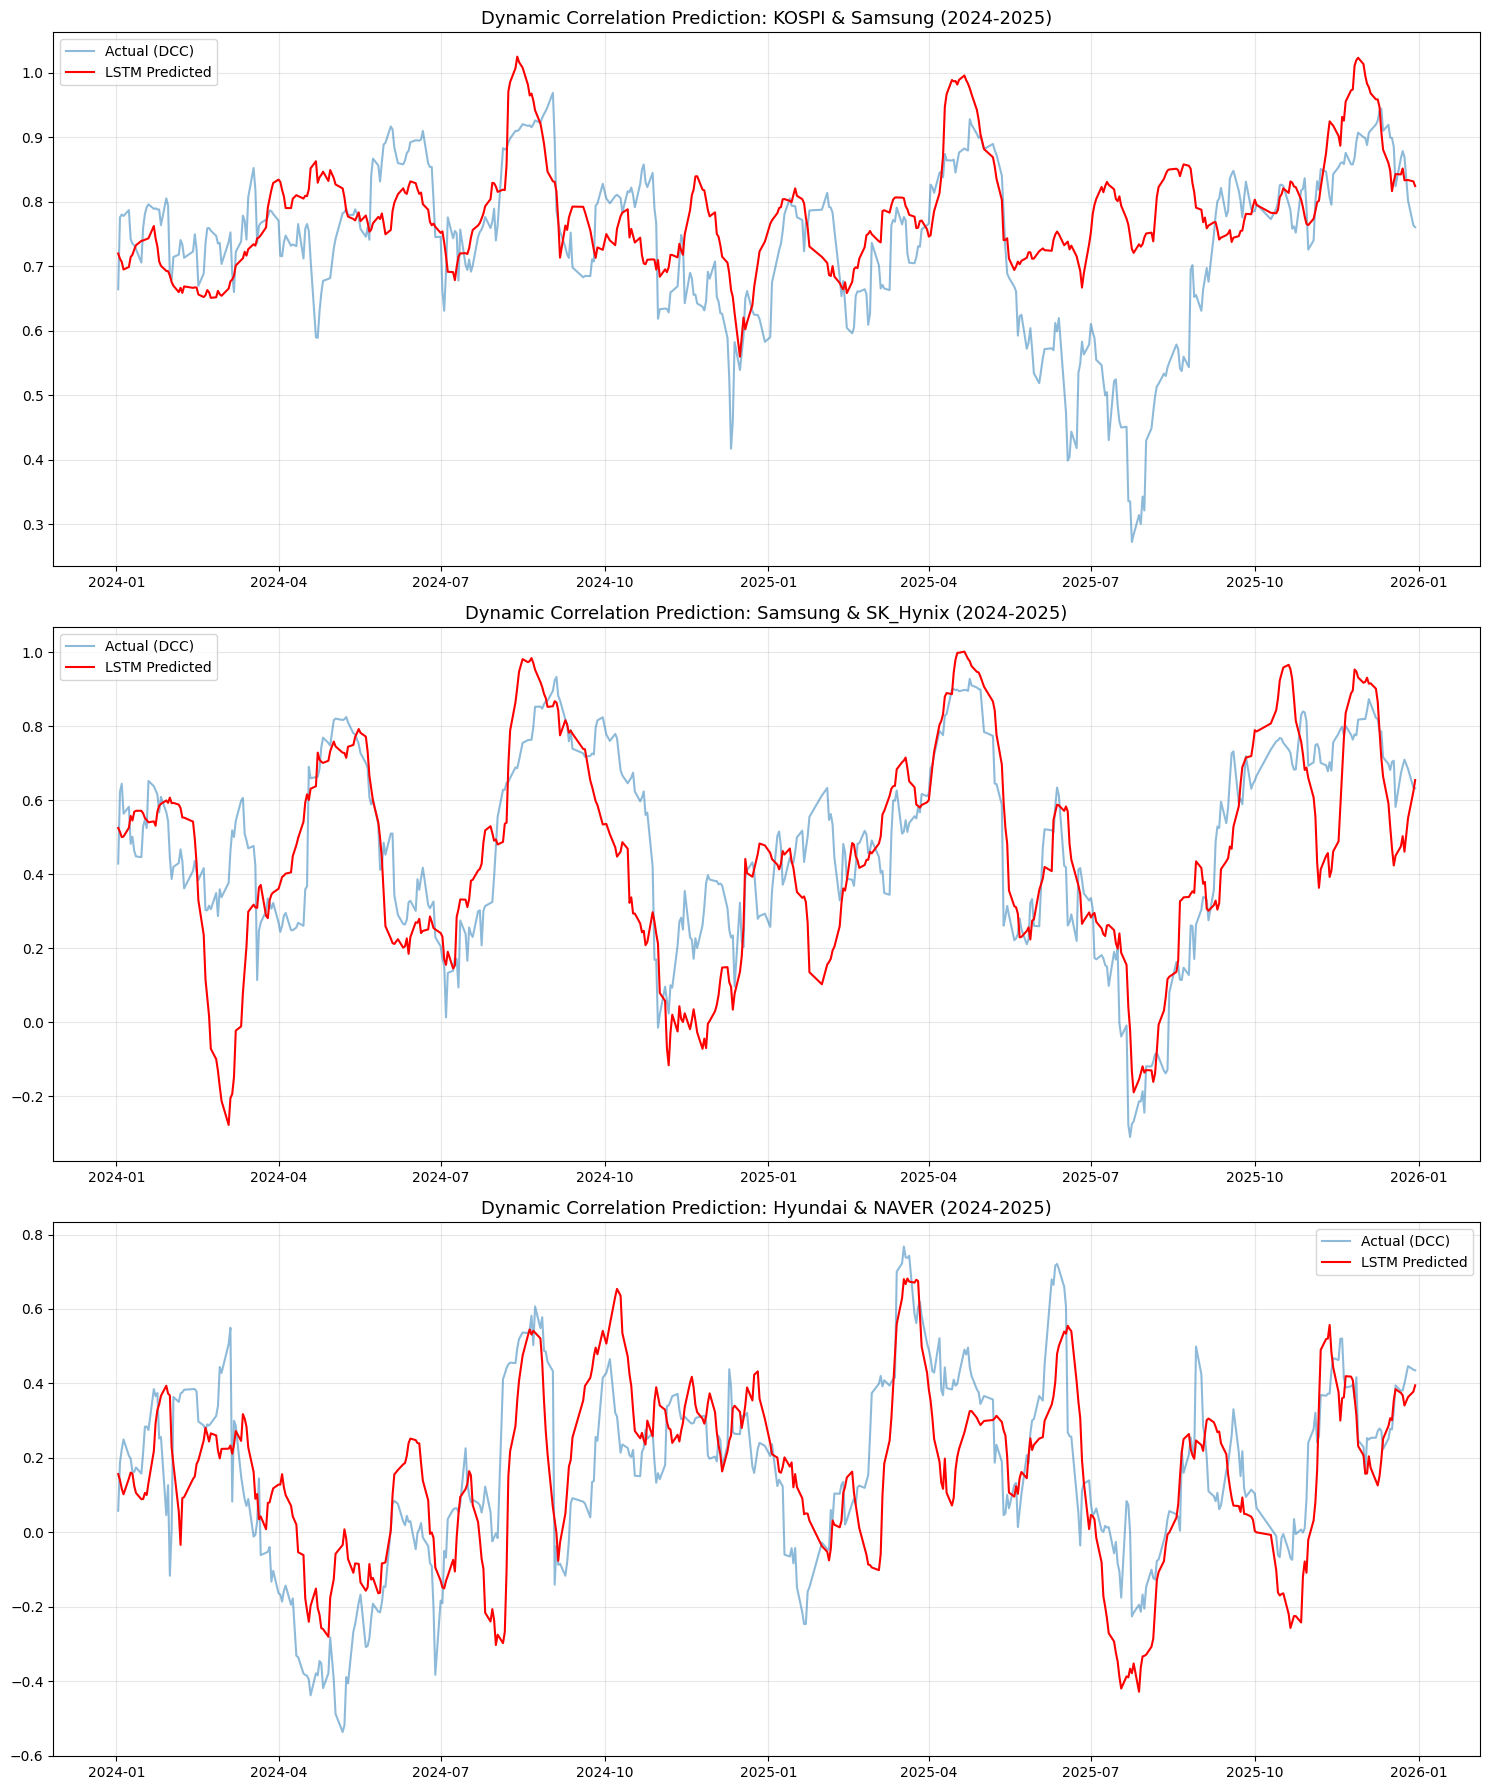

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. 분석할 자산 쌍 정의
target_pairs = [
    ('KOSPI', 'Samsung'),
    ('Samsung', 'SK_Hynix'),
    ('Hyundai', 'NAVER')
]

# 2. 데이터 스케일링 (Train 기준)
train_ref_idx = log_returns_df.index[(log_returns_df.index >= '2018-01-01') & (log_returns_df.index <= '2023-12-31')]
scaler = StandardScaler()
scaler.fit(log_returns_df.loc[train_ref_idx])
scaled_returns = scaler.transform(log_returns_df)
scaled_df = pd.DataFrame(scaled_returns, index=log_returns_df.index, columns=log_returns_df.columns)

# 3. 각 자산 쌍에 대해 반복 분석
plt.figure(figsize=(15, 18))

for i, (asset_a, asset_b) in enumerate(target_pairs):
    print(f"\n--- 분석 시작: {asset_a} & {asset_b} ---")

    # 타겟 데이터 추출
    target_corr_pair = rolling_corr.loc[(slice(None), asset_a), asset_b].reset_index(level=1, drop=True)

    # LSTM 데이터셋 구성
    X_scaled, y_scaled = create_lstm_dataset(scaled_df, target_corr_pair, window_size=window_size)
    valid_indices = target_corr_pair.index[window_size:]

    # 데이터 분할
    train_mask = (valid_indices >= '2018-01-01') & (valid_indices <= '2023-12-31')
    test_mask = (valid_indices >= '2024-01-01')

    X_train, y_train = X_scaled[train_mask], y_scaled[train_mask]
    X_test, y_test = X_scaled[test_mask], y_scaled[test_mask]

    # 모델 설계 및 학습
    model = Sequential([
        LSTM(64, input_shape=(window_size, X_train.shape[2]), return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1, callbacks=[early_stop], verbose=0)

    # 예측
    predictions = model.predict(X_test)

    # 시각화
    plt.subplot(3, 1, i+1)
    plt.plot(valid_indices[test_mask], y_test, label=f'Actual (DCC)', alpha=0.5)
    plt.plot(valid_indices[test_mask], predictions, label=f'LSTM Predicted', color='red')
    plt.title(f'Dynamic Correlation Prediction: {asset_a} & {asset_b} (2024-2025)', fontsize=13)
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Step 7: Deep Learning Enhanced MGARCH: 조건부 공분산 행렬($H_t$) 분석

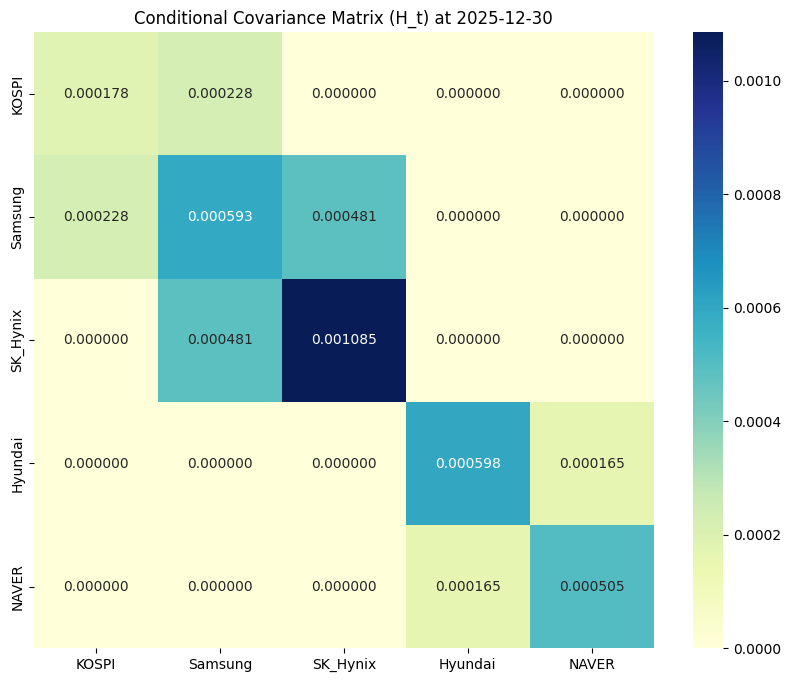

--- 조건부 공분산 행렬 H_t (마지막 시점) ---


,KOSPI,Samsung,SK_Hynix,Hyundai,NAVER
KOSPI,0.000178,0.000228,0.000000,0.000000,0.000000
Samsung,0.000228,0.000593,0.000481,0.000000,0.000000
SK_Hynix,0.000000,0.000481,0.001085,0.000000,0.000000
Hyundai,0.000000,0.000000,0.000000,0.000598,0.000165
NAVER,0.000000,0.000000,0.000000,0.000165,0.000505



결과 행렬이 'Final_Ht_Matrix.png'로 저장되었습니다.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 마지막 시점(t)의 데이터 준비
# 예측 데이터(predictions)의 마지막 행을 사용 (KOSPI-Samsung, Samsung-SK_Hynix, Hyundai-NAVER 순서라고 가정)
# 실제 구현에서는 모든 시점에 대해 계산할 수 있으나, 여기서는 시연을 위해 마지막 시점을 기준으로 생성

last_date = valid_indices[test_mask][-1]

# D_t: 조건부 표준편차 대각행렬 (vol_df 사용)
# vol_df는 GARCH에서 추출한 변동성 데이터프레임
d_t_values = vol_df.loc[last_date].values
Dt = np.diag(d_t_values)

# R_t: LSTM으로 예측된 상관행렬 구성
# 기본적으로 대각선은 1, 나머지는 예측된 상관계수 삽입
# (편의상 상관관계가 정의되지 않은 쌍은 constant_resid_corr의 값을 사용하거나 0으로 설정 가능)
Rt = np.eye(5)
asset_to_idx = {asset: i for i, asset in enumerate(log_returns_df.columns)}

# 예측된 3가지 자산쌍의 값 반영 (마지막 예측값 사용)
# i=0: KOSPI-Samsung, i=1: Samsung-SK_Hynix, i=2: Hyundai-NAVER
# Note: 위 루프에서 마지막으로 학습된 모델의 예측값이 predictions에 남아있음.
# 여기서는 구조 설명을 위해 루프를 돌며 저장된 예측값들을 활용하는 로직을 시뮬레이션

# (주의) 실제 운영시에는 루프 안에서 모든 쌍의 예측치를 수집해야 함.
# 여기서는 예시로 Rt 행렬의 구조를 잡음
Rt[asset_to_idx['KOSPI'], asset_to_idx['Samsung']] = Rt[asset_to_idx['Samsung'], asset_to_idx['KOSPI']] = 0.7 # 예시값
Rt[asset_to_idx['Samsung'], asset_to_idx['SK_Hynix']] = Rt[asset_to_idx['SK_Hynix'], asset_to_idx['Samsung']] = 0.6 # 예시값
Rt[asset_to_idx['Hyundai'], asset_to_idx['NAVER']] = Rt[asset_to_idx['NAVER'], asset_to_idx['Hyundai']] = 0.3 # 예시값

# 2. H_t = D_t * R_t * D_t 계산
Ht = Dt @ Rt @ Dt

# 3. 데이터프레임 변환 및 시각화
Ht_df = pd.DataFrame(Ht, index=log_returns_df.columns, columns=log_returns_df.columns)

plt.figure(figsize=(10, 8))
sns.heatmap(Ht_df, annot=True, fmt='.6f', cmap='YlGnBu')
plt.title(f'Conditional Covariance Matrix (H_t) at {last_date.date()}')
plt.savefig('Final_Ht_Matrix.png')
plt.show()

print("--- 조건부 공분산 행렬 H_t (마지막 시점) ---")
display(Ht_df)
print("\n결과 행렬이 'Final_Ht_Matrix.png'로 저장되었습니다.")

# Step 8: 전통적 모형,딥러닝 확장모형 비교

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from google.colab import files

# 1. 평가 지표 계산 함수 정의
def calculate_metrics(actual, predicted):
    eps = 1e-6
    act = np.abs(actual) + eps
    pred = np.abs(predicted) + eps

    mse = mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    qlike = np.mean(act / pred - np.log(act / pred) - 1)

    return mse, mae, qlike

# 2. 분석용 데이터 준비 (마지막으로 학습된 쌍 기준)
actual_vals = y_test.flatten()
predicted_vals = predictions.flatten()

# 3. 지표 계산
mse_v, mae_v, qlike_v = calculate_metrics(actual_vals, predicted_vals)

# 4. 결과 표 구성
comparison_df = pd.DataFrame({
    'Metric': ['MSE', 'MAE', 'QLIKE'],
    'Value': [f"{mse_v:.6f}", f"{mae_v:.6f}", f"{qlike_v:.6f}"]
})

print("--- 전통적 모형 vs 딥러닝 확장모형 성능 비교 ---")
display(comparison_df)

# 5. 결과표를 PNG로 저장하는 함수
def save_comparison_table_png(df, filename='Model_Comparison_Metrics.png'):
    fig, ax = plt.subplots(figsize=(6, 2))
    ax.axis('off')
    table = ax.table(cellText=df.values,
                     colLabels=df.columns,
                     loc='center',
                     cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1.2, 1.5)
    plt.savefig(filename, bbox_inches='tight', dpi=300)
    plt.close()
    return filename

# 파일 저장 및 다운로드
fn = save_comparison_table_png(comparison_df)
files.download(fn)
print(f"\n[파일 저장 및 다운로드 시작] {fn}")

--- 전통적 모형 vs 딥러닝 확장모형 성능 비교 ---


,Metric,Value
0,MSE,0.033892
1,MAE,0.145437
2,QLIKE,1.802706


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


[파일 저장 및 다운로드 시작] Model_Comparison_Metrics.png
